# Wildfire ignition risk for British Columbia: walkthrough

This notebook reads the artefacts produced by the `wildfire` package (`make data train report`) and walks through
the problem, the features, and what the model does and does not learn. All heavy lifting lives in the package; the
notebook is for looking at results.

**Task.** For each ~0.5° grid cell and each week of the Apr–Oct season: *will at least one wildfire ignition occur in the next 7 days?*

**Data (all open, no API key).** BC Wildfire Service ignition records (labels) · NASA POWER daily weather (features) · BC provincial boundary.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from wildfire.config import load_config
from wildfire.train import load_dataset, add_rate_features
from wildfire.features import FEATURE_GROUPS

cfg = load_config()
pd.set_option("display.width", 160)
df, enc = add_rate_features(load_dataset(cfg))
print(f"{len(df):,} cell-weeks | {df.cell_id.nunique()} cells | {df.year.min()}-{df.year.max()} | positive rate {df.label.mean():.1%}")
df.groupby("split").agg(rows=("label", "size"), years=("year", lambda s: f"{s.min()}-{s.max()}"), positive_rate=("label", "mean")).round(3)

401,016 cell-weeks | 616 cells | 2005-2025 | positive rate 5.0%


,rows,years,positive_rate
split,,,
test,95480,2021-2025,0.055
train,267344,2005-2018,0.051
val,38192,2019-2020,0.027


## 1. The target is rare, seasonal and spatially concentrated

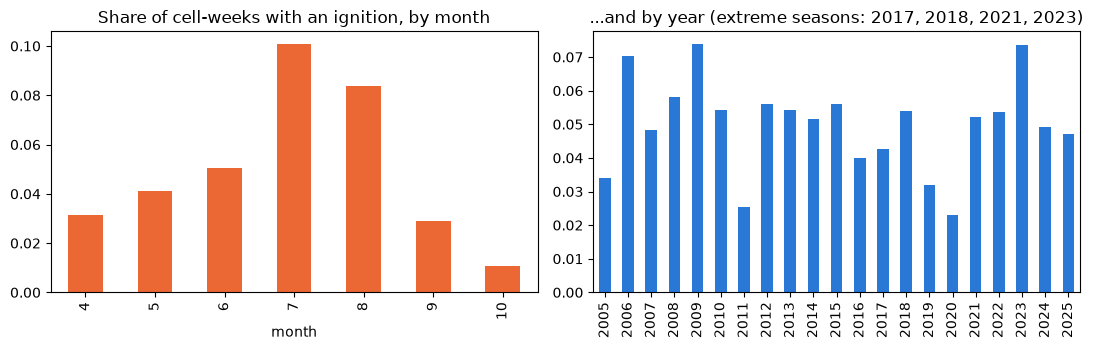

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df.groupby(df.date.dt.month).label.mean().plot.bar(ax=ax[0], color="#eb6834"); ax[0].set(title="Share of cell-weeks with an ignition, by month", xlabel="month")
df.groupby("year").label.mean().plot.bar(ax=ax[1], color="#2a78d6"); ax[1].set(title="...and by year (extreme seasons: 2017, 2018, 2021, 2023)", xlabel="")
plt.tight_layout()

## 2. Features

Every feature at date *t* uses information up to and including *t*; the label covers days *t+1 … t+7* (unit tests enforce this).
Groups: raw **weather** (temperature, humidity from dew point, VPD, wind, rolling rainfall, days since rain), the **Canadian Fire Weather Index
System** codes (FFMC, DMC, DC, ISI, BUI, FWI, implemented from Van Wagner 1987 and validated against the published reference values),
**location/terrain**, **seasonality**, **recent ignitions** (this cell, neighbours), and a **local ignition history** rate (leave-one-year-out so training rows never see their own year).

In [3]:
for g, fs in FEATURE_GROUPS.items():
    print(f"{g:26s} {', '.join(fs)}")
df[[f for fs in FEATURE_GROUPS.values() for f in fs]].describe().T[["mean", "std", "min", "max"]].round(2)

Weather                    tmax, rh, vpd, wind_kmh, precip, precip_7d, precip_30d, days_since_rain, tmax_7d, rh_min_7d
Fire Weather Index codes   ffmc, dmc, dc, isi, bui, fwi
Location / terrain         lat, lon, elevation
Seasonality                doy_sin, doy_cos
Recent ignitions           ign_cell_7d, ign_cell_30d, ign_nbr_30d
Local ignition history     rate_cell_month, rate_cell


,mean,std,min,max
tmax,11.35,7.78,-19.91,36.88
rh,61.55,15.55,11.41,99.86
vpd,6.50,5.54,0.01,49.15
wind_kmh,11.59,6.82,2.12,90.76
precip,2.93,4.85,0.00,108.42
precip_7d,20.04,19.96,0.00,286.13
precip_30d,83.89,57.94,1.01,784.84
days_since_rain,1.79,3.17,0.00,60.00
tmax_7d,11.34,7.29,-16.63,38.01
rh_min_7d,50.76,13.75,10.59,97.15


## 3. Does the model beat 'it's July in the interior'?

The fair baseline is **climatology**: the historical ignition rate for that cell and month. It already knows where and when fires usually happen.

In [4]:
m = json.load(open(cfg.path("reports_dir") / "metrics.json"))
t = pd.DataFrame(m["test"])[["roc_auc", "pr_auc", "brier_skill", "ece", "capture_top5", "lift_top5"]]
t.round(3)

,roc_auc,pr_auc,brier_skill,ece,capture_top5,lift_top5
Climatology,0.861,0.281,0.142,0.005,0.311,6.226
Logistic regression,0.874,0.313,0.156,0.006,0.336,6.716
Random forest,0.886,0.324,0.174,0.003,0.347,6.940
Gradient boosting,0.887,0.325,0.172,0.004,0.347,6.948
Gradient boosting (calibrated),0.886,0.310,0.152,0.018,0.343,6.864
Random forest (calibrated),0.886,0.311,0.153,0.018,0.343,6.861
Logistic regression (calibrated),0.874,0.304,0.131,0.022,0.332,6.632


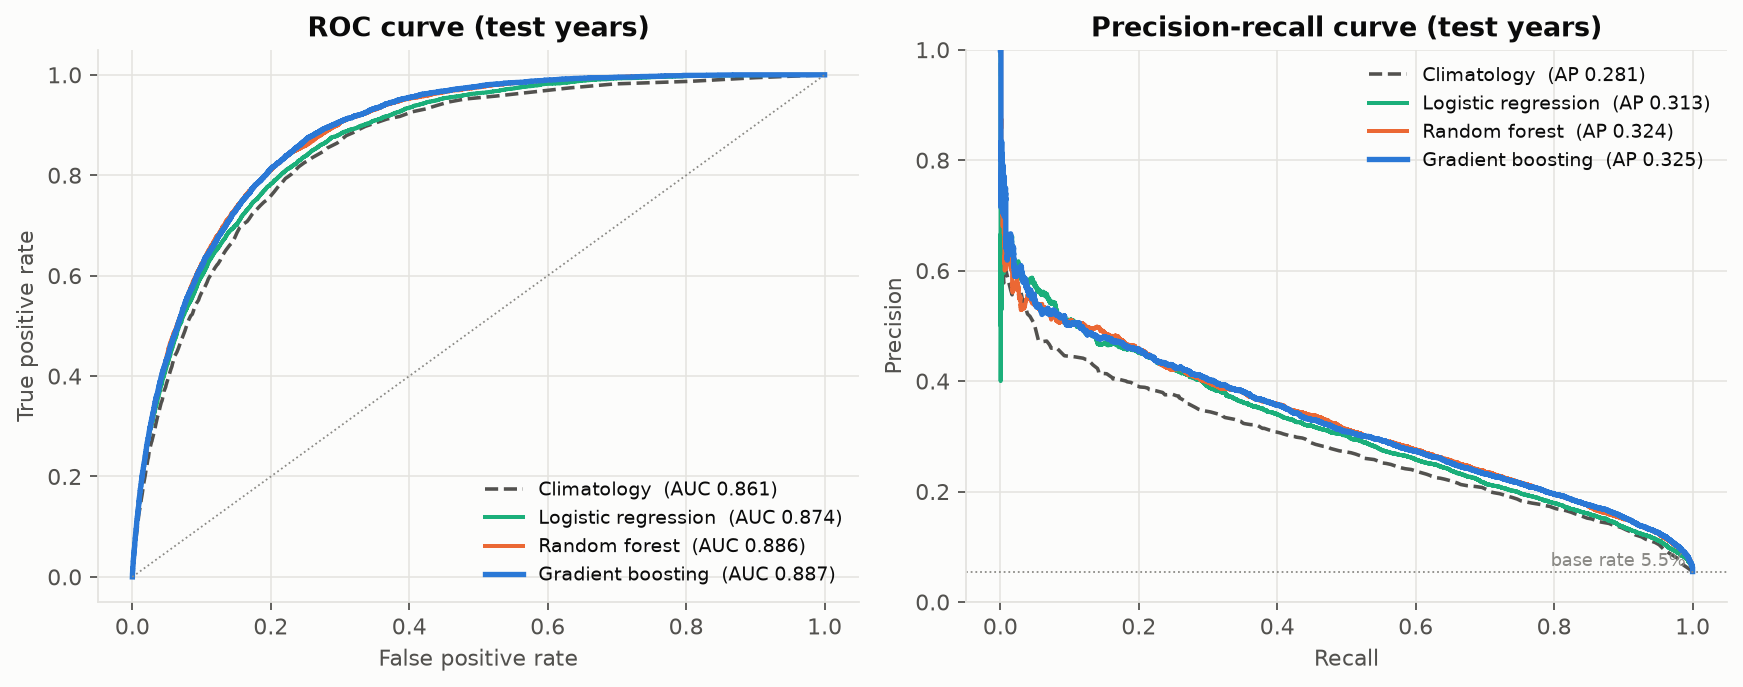

In [5]:
display(Image(str(cfg.path("reports_dir", "figures", "model_comparison.png"))))

**Reading this honestly.** Climatology is strong (ROC-AUC 0.86). The weather-aware models improve on it by a small but statistically
clear margin (see the bootstrap intervals in the README). Most of the predictive power is *where and when*; weather adds the week-to-week signal.

In [6]:
b = pd.DataFrame(**m["bootstrap"])
b[b.metric.str.contains("- ref")].round(3)

,model,metric,mean,lo,hi
4,Logistic regression,roc_auc - ref,0.013,0.005,0.022
5,Logistic regression,pr_auc - ref,0.033,0.016,0.047
8,Random forest,roc_auc - ref,0.026,0.019,0.033
9,Random forest,pr_auc - ref,0.044,0.025,0.060
12,Gradient boosting,roc_auc - ref,0.026,0.020,0.033
13,Gradient boosting,pr_auc - ref,0.044,0.021,0.064


## 4. What does each feature group add?

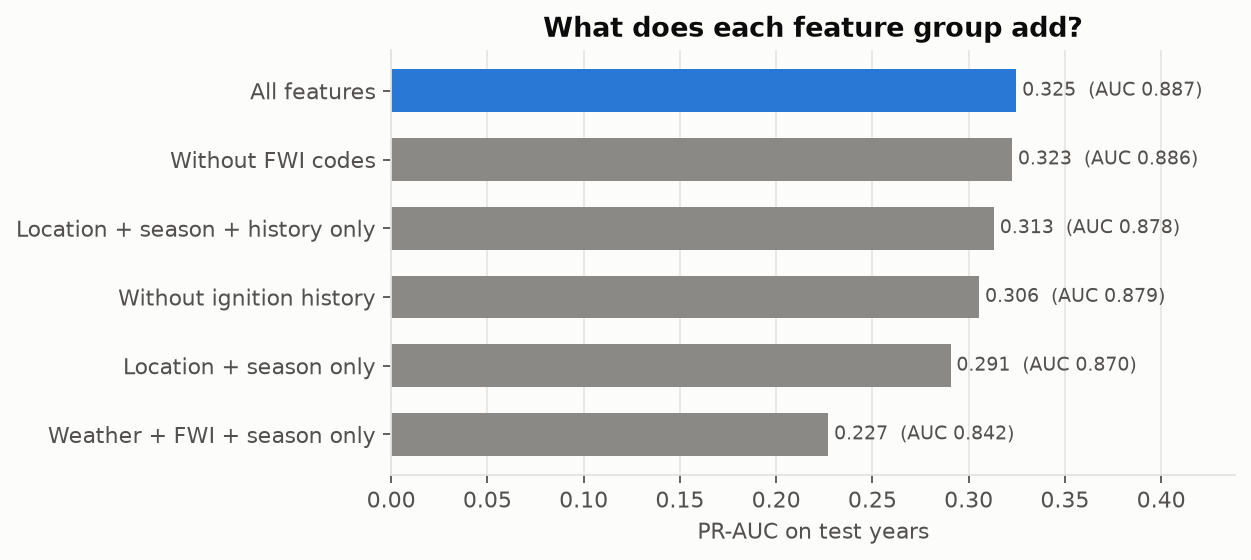

In [7]:
display(Image(str(cfg.path("reports_dir", "figures", "ablation.png"))))

Dropping the FWI codes costs almost nothing (the raw weather features carry the same information), but removing *all* weather and FWI features does cost skill.
The big missing ingredient is almost certainly **lightning** (the dominant natural ignition cause in BC) and **human access** (roads, settlements); neither is in the data here.

## 5. What drives individual predictions? (SHAP)

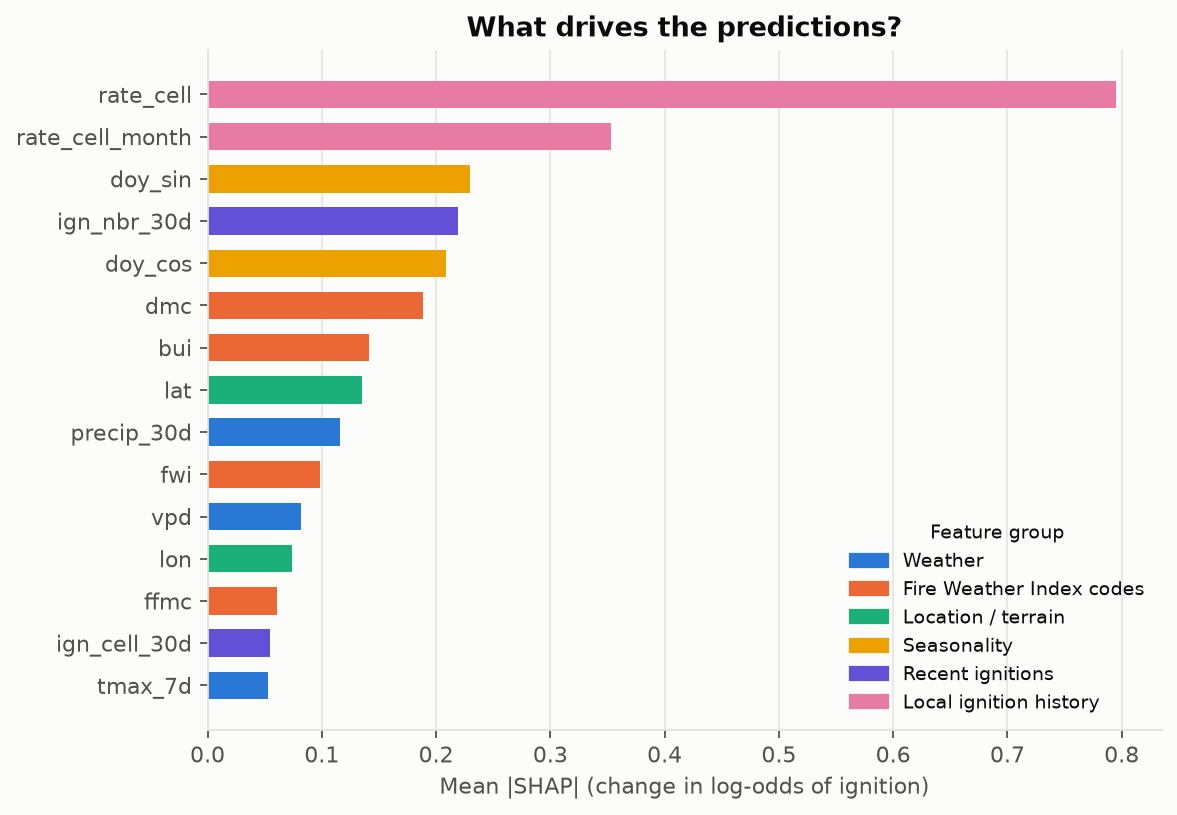

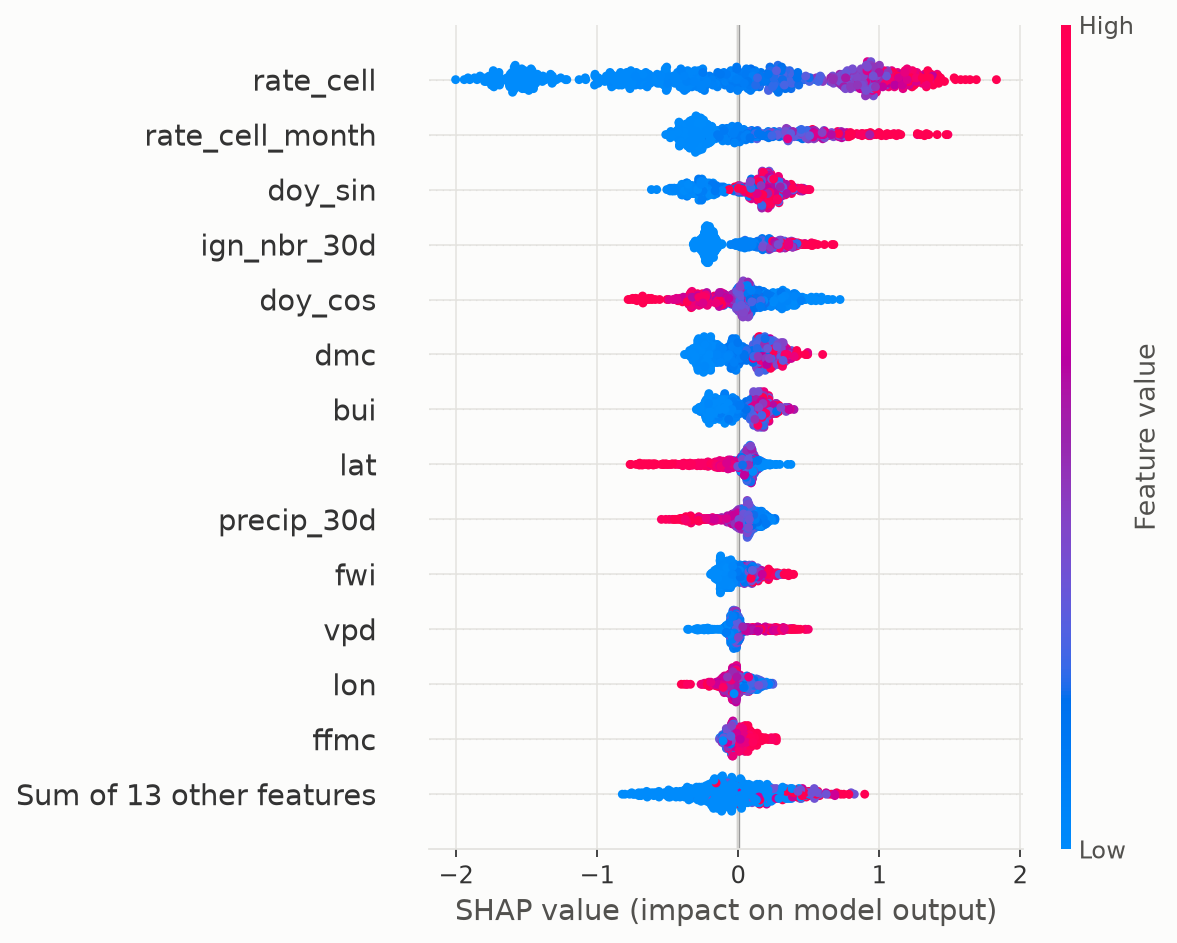

In [8]:
display(Image(str(cfg.path("reports_dir", "figures", "shap_importance.png"))))
display(Image(str(cfg.path("reports_dir", "figures", "shap_beeswarm.png"))))

## 6. Generalisation checks

Spatial-block CV (hold out 2°x2° blocks; local-history features removed):


roc_auc        pr_auc        brier_skill       
                                  mean    std   mean    std        mean    std
model                                                                         
Climatology (no local history)   0.673  0.021  0.081  0.033      -0.000  0.022
Gradient boosting                0.885  0.016  0.304  0.076       0.159  0.040

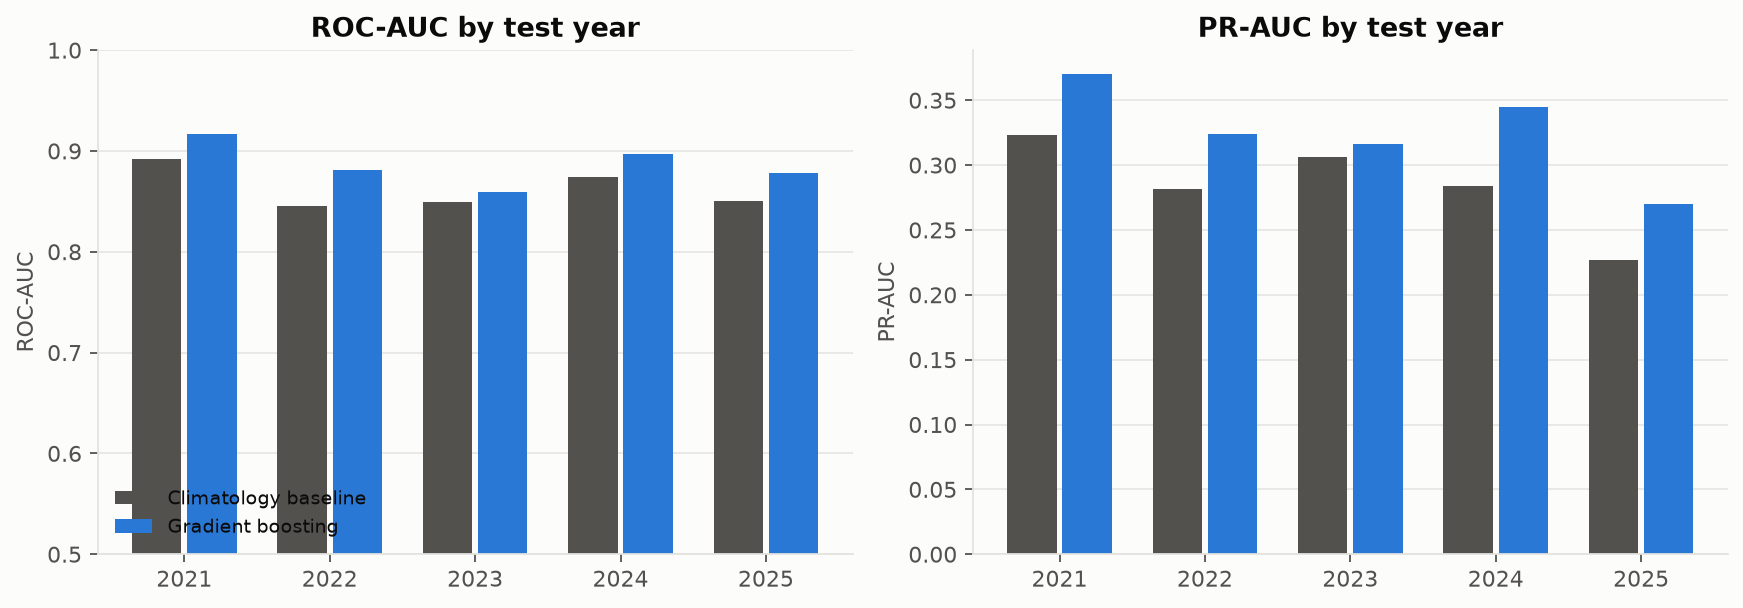

In [9]:
sp = pd.DataFrame(**m["spatial_cv"])
print("Spatial-block CV (hold out 2°x2° blocks; local-history features removed):")
display(sp.groupby("model")[["roc_auc", "pr_auc", "brier_skill"]].agg(["mean", "std"]).round(3))
display(Image(str(cfg.path("reports_dir", "figures", "per_year.png"))))

## 7. Calibration, and a negative result

Isotonic recalibration on the 2019–20 validation years made the model *worse* on the test years: those validation years were quiet, the test years were not. The raw model was already well calibrated, so it is the one deployed.

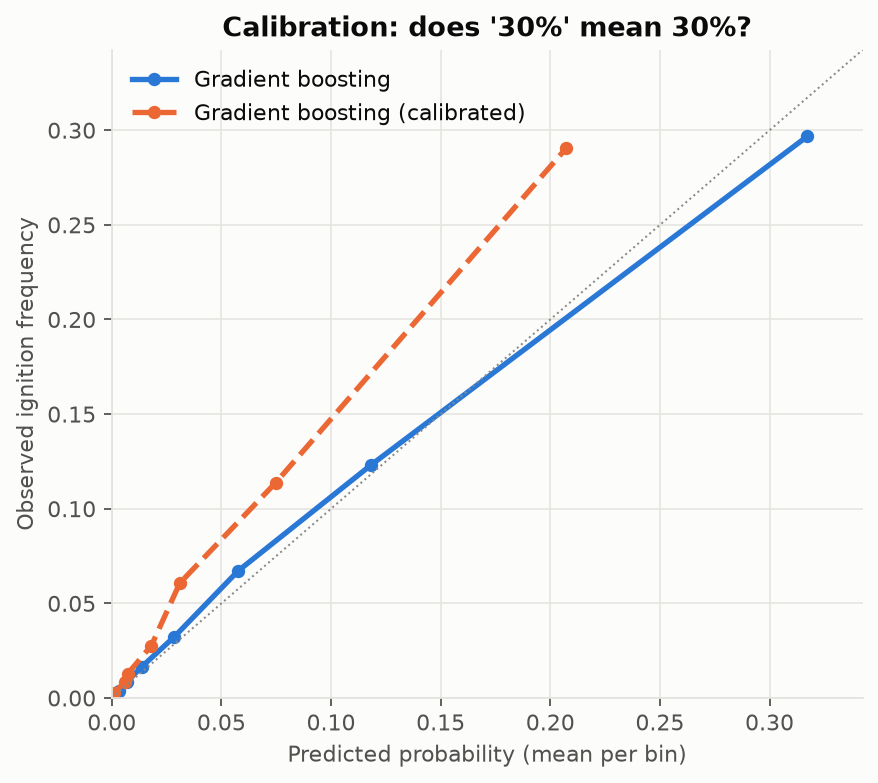

In [10]:
display(Image(str(cfg.path("reports_dir", "figures", "calibration.png"))))

## 8. A held-out week on the map

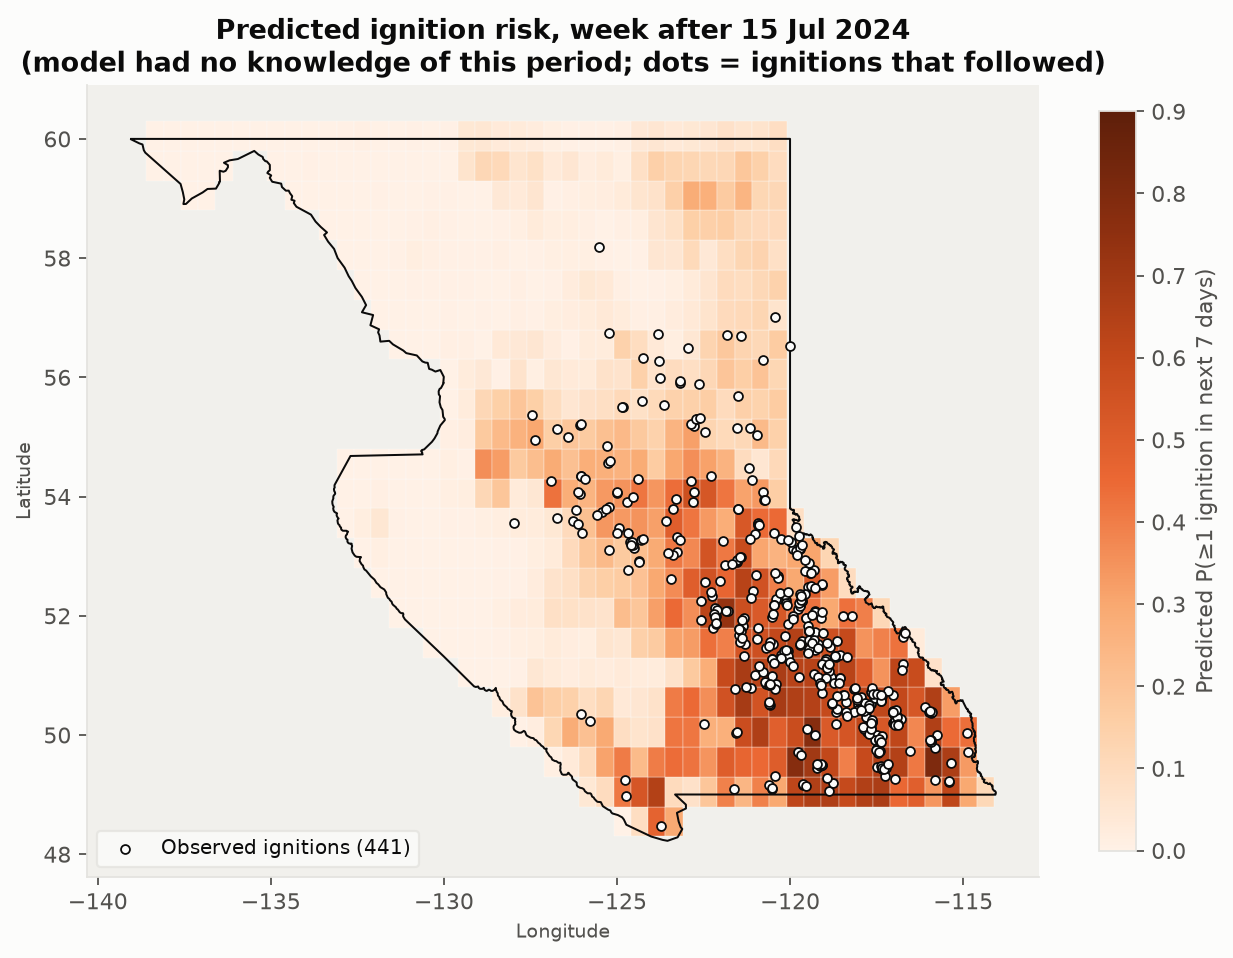

In [11]:
display(Image(str(cfg.path("reports_dir", "figures", "risk_map_peak_week.png"))))